# Ingatlanár-becslés — modellezés és kiértékelés

Ez a notebook a `01_eda_and_preprocessing.ipynb` kimenetére
(`data/properties_preprocessed.csv`) épül, és a `plan.md`-ben kijelölt
fő irányt viszi végig: **regresszió az ár (pontosabban `log_price`) becslésére**.

Három, egymásra épülő kísérletet futtatunk:

1. **Teljes adathalmaz** (minden ingatlantípus, a két 1-elemű osztály kivételével) —
   három modell (Lineáris regresszió, Ridge, Random Forest) összehasonlítása.
2. **Szűkített adathalmaz** (csak `ház` és `lakás`) — mivel a `telek` és `nyaralo`
   kategóriák más piaci logikát követnek és a `area_sqm` skálája is eltér
   (egy telek m²-ben sokkal nagyobb, mint egy lakás alapterülete), megnézzük,
   javít-e a homogénebb részhalmazra szűkítés.
3. **Kiugró értékek eltávolítása** a szűkített adathalmazon — az előfeldolgozó
   notebookban már jelölt (1./99. percentilis alapján kiugrónak jelölt) sorok
   kihagyásának hatása.

Minden kísérletnél 80/20 train/test felosztást és 5-fold keresztvalidációt
használunk a train részen, a végső kiértékelés pedig a (modellillesztésben
sosem látott) teszthalmazon történik.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)
RANDOM_STATE = 42

df = pd.read_csv("../data/properties_preprocessed.csv")
print("Betöltött (előfeldolgozott) sorok, oszlopok:", df.shape)


Betöltött (előfeldolgozott) sorok, oszlopok: (476, 44)


## 1. Kísérlet — teljes adathalmaz, modellösszehasonlítás

A `sorhaz` és `beruhazas` típusokból csak 1-1 hirdetés van, ezekre semmilyen
modell nem tud általánosítani (sem tanítani, sem érdemben kiértékelni rajtuk),
ezért ezt a két sort kihagyjuk a modellezésből — ez összhangban van az EDA
notebook 3. pontjának következtetésével.

Jellemzők (feature-ök):

- `log_area_sqm` — log-transzformált alapterület,
- `rooms`, `rooms_missing` — (imputált) szobaszám + hiány-jelző,
- `is_budapest`, `has_coords`, `dist_to_bp_km` — helyszín-jellemzők,
- `type_lakas`, `type_nyaralo`, `type_telek` — ingatlantípus one-hot (a `ház`
  a referenciakategória, ezért nincs rá külön oszlop).

A `dist_to_bp_km`-nél a koordináta nélküli sorokra a medián távolsággal
pótolunk (ezeket a `has_coords=0` flag jelzi a modell felé).


In [2]:
df_model = df[~df["type_sorhaz"].astype(bool) & ~df["type_beruhazas"].astype(bool)].copy()
df_model["dist_to_bp_km"] = df_model["dist_to_bp_km"].fillna(df_model["dist_to_bp_km"].median())
print("Modellezésbe bekerülő sorok (sorhaz/beruhazas nélkül):", df_model.shape)

FEATURES_FULL = [
    "log_area_sqm", "rooms", "rooms_missing",
    "is_budapest", "has_coords", "dist_to_bp_km",
    "type_lakas", "type_nyaralo", "type_telek",
]
TARGET = "log_price"


Modellezésbe bekerülő sorok (sorhaz/beruhazas nélkül): (474, 44)


In [3]:
def evaluate_models(data, features, target=TARGET, label=""):
    """Train/test split + 5-fold CV + teszt-kiértékelés egy adott feature-halmazon.

    Visszaadja a fitted modelleket és egy összehasonlító DataFrame-et, hogy a
    teszthalmazon kapott predikciókat/reziduumokat is tovább lehessen vizsgálni.
    """
    X = data[features]
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )

    models = {
        "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge (alpha=1.0)": make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=RANDOM_STATE)),
        "RandomForest": RandomForestRegressor(
            n_estimators=300, max_depth=6, random_state=RANDOM_STATE
        ),
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    fitted = {}
    for name, model in models.items():
        cv_mae = -cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_absolute_error")
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        mae_log = mean_absolute_error(y_test, pred)
        rmse_log = mean_squared_error(y_test, pred) ** 0.5
        r2 = r2_score(y_test, pred)

        pred_huf = np.expm1(pred)
        true_huf = np.expm1(y_test)
        mae_huf = mean_absolute_error(true_huf, pred_huf)
        mape = np.mean(np.abs((true_huf - pred_huf) / true_huf)) * 100

        rows.append({
            "modell": name,
            "CV MAE (log, train)": round(cv_mae.mean(), 3),
            "CV MAE std": round(cv_mae.std(), 3),
            "teszt MAE (log)": round(mae_log, 3),
            "teszt RMSE (log)": round(rmse_log, 3),
            "teszt R2": round(r2, 3),
            "teszt MAE (HUF)": round(mae_huf),
            "teszt MAPE (%)": round(mape, 1),
        })
        fitted[name] = model

    result = pd.DataFrame(rows).set_index("modell")
    print(f"=== {label} (n={len(data)}, train={len(X_train)}, test={len(X_test)}) ===")
    print(result)
    return fitted, result, (X_train, X_test, y_train, y_test)


fitted_full, result_full, split_full = evaluate_models(
    df_model, FEATURES_FULL, label="1. kísérlet: teljes adathalmaz"
)


=== 1. kísérlet: teljes adathalmaz (n=474, train=379, test=95) ===
                   CV MAE (log, train)  CV MAE std  teszt MAE (log)  \
modell                                                                
LinearRegression                 0.395       0.053            0.419   
Ridge (alpha=1.0)                0.395       0.053            0.418   
RandomForest                     0.381       0.036            0.358   

                   teszt RMSE (log)  teszt R2  teszt MAE (HUF)  teszt MAPE (%)  
modell                                                                          
LinearRegression              0.550     0.588         33381497            53.6  
Ridge (alpha=1.0)             0.549     0.589         33326419            53.5  
RandomForest                  0.504     0.653         29114286            50.4  


### Értelmezés

A három modell közül a **Random Forest** adja a legjobb teszteredményt
(alacsonyabb hiba, magasabb R²), ami arra utal, hogy az ár és a jellemzők
(elsősorban terület és helyszín) kapcsolata **nem tisztán lineáris** —
ezt egy fastruktúra-alapú modell jobban tudja kezelni, mint a lineáris/Ridge
regresszió. A hiba (MAPE) viszont még így is magas: ennek egy fontos oka,
hogy a `telek` (földterület) és a `nyaralo` (üdülő) kategóriák más piaci
logikát követnek, és a `area_sqm` jelentése is más (telekméret vs.
lakóterület) — ezt vizsgáljuk meg a 2. kísérletben.


## 2. Kísérlet — szűkített adathalmaz: csak `ház` és `lakás`

Ez a két kategória a legnagyobb minta (232 + 204 ≈ a teljes adat 92%-a), és
mindkettőnél a `area_sqm` ugyanazt jelenti (lakóterület), így konzisztensebb
tanulási feladatot ad. A `type_lakas` egyetlen dummy oszlop marad (a `ház` a
referencia), a `type_nyaralo`/`type_telek` oszlopokra itt nincs szükség.


In [4]:
FEATURES_RESTRICTED = [
    "log_area_sqm", "rooms", "rooms_missing",
    "is_budapest", "has_coords", "dist_to_bp_km",
    "type_lakas",
]

df_haz_lakas = df_model[
    df_model["type_haz"].astype(bool) | df_model["type_lakas"].astype(bool)
].copy()

fitted_restricted, result_restricted, split_restricted = evaluate_models(
    df_haz_lakas, FEATURES_RESTRICTED, label="2. kísérlet: csak ház + lakás"
)


=== 2. kísérlet: csak ház + lakás (n=435, train=348, test=87) ===
                   CV MAE (log, train)  CV MAE std  teszt MAE (log)  \
modell                                                                
LinearRegression                 0.402       0.048            0.355   
Ridge (alpha=1.0)                0.402       0.048            0.355   
RandomForest                     0.372       0.056            0.263   

                   teszt RMSE (log)  teszt R2  teszt MAE (HUF)  teszt MAPE (%)  
modell                                                                          
LinearRegression              0.452     0.553         32204435            39.4  
Ridge (alpha=1.0)             0.452     0.553         32238221            39.5  
RandomForest                  0.400     0.649         26737100            29.1  


### Értelmezés

A homogénebb részhalmazra szűkítés **minden modellnél javított** — a
Random Forest teszt-MAPE-je kb. a felére csökkent az 1. kísérlethez képest.
Ez megerősíti, hogy a `telek`/`nyaralo` kategóriák belevétele zajt
("más piaci logika") vitt a modellbe. A fennmaradó hibát vizsgáljuk tovább
kiugró értékek és feature-fontosság szempontjából.


## 3. Kísérlet — kiugró értékek hatása

Az előfeldolgozó notebook `price_outlier` / `area_outlier` flag-eket jelölt
(1./99. percentilis alapján), de **nem dobta el automatikusan** a sorokat —
itt megnézzük, mi történik, ha a modellezésből kihagyjuk őket.


In [5]:
df_no_outliers = df_haz_lakas[
    (df_haz_lakas["price_outlier"] == 0) & (df_haz_lakas["area_outlier"] == 0)
].copy()
print(f"Kiugró érték nélkül: {len(df_no_outliers)} sor (eredetileg {len(df_haz_lakas)})")

fitted_clean, result_clean, split_clean = evaluate_models(
    df_no_outliers, FEATURES_RESTRICTED, label="3. kísérlet: ház+lakás, kiugró értékek nélkül"
)


Kiugró érték nélkül: 426 sor (eredetileg 435)


=== 3. kísérlet: ház+lakás, kiugró értékek nélkül (n=426, train=340, test=86) ===
                   CV MAE (log, train)  CV MAE std  teszt MAE (log)  \
modell                                                                
LinearRegression                 0.371       0.021            0.363   
Ridge (alpha=1.0)                0.371       0.021            0.363   
RandomForest                     0.306       0.036            0.249   

                   teszt RMSE (log)  teszt R2  teszt MAE (HUF)  teszt MAPE (%)  
modell                                                                          
LinearRegression              0.470     0.459         32302663            38.7  
Ridge (alpha=1.0)             0.470     0.460         32284382            38.7  
RandomForest                  0.339     0.719         21339129            27.2  


## Összehasonlító táblázat (a 3 kísérlet Random Forest eredményei)

A dokumentációban (`project_dokumentacio.md`) bemutatott fő összehasonlító
táblázat ebből a három futásból származik.


In [6]:
summary = pd.DataFrame({
    "1. teljes adat": result_full.loc["RandomForest"],
    "2. ház+lakás": result_restricted.loc["RandomForest"],
    "3. ház+lakás, outlier nélkül": result_clean.loc["RandomForest"],
}).T
summary


,"CV MAE (log, train)",CV MAE std,teszt MAE (log),teszt RMSE (log),teszt R2,teszt MAE (HUF),teszt MAPE (%)
1. teljes adat,0.381,0.036,0.358,0.504,0.653,29114286.0,50.4
2. ház+lakás,0.372,0.056,0.263,0.400,0.649,26737100.0,29.1
"3. ház+lakás, outlier nélkül",0.306,0.036,0.249,0.339,0.719,21339129.0,27.2


## Feature-fontosság (Random Forest, 3. kísérlet)

Megnézzük, mely jellemzők vezérlik leginkább a Random Forest predikcióit a
legjobb (3. kísérlet) beállításon.


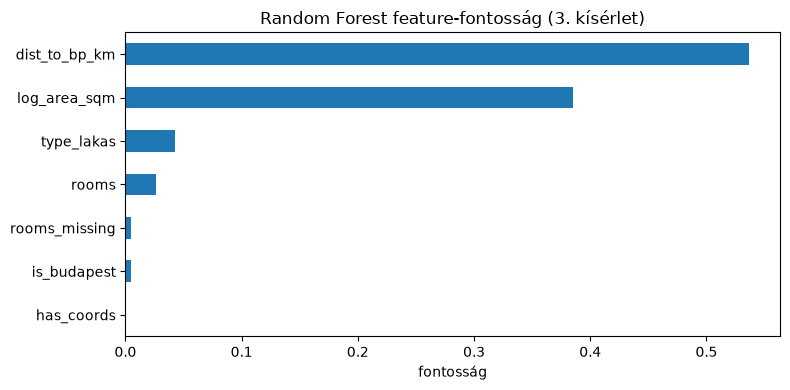

dist_to_bp_km    0.536484
log_area_sqm     0.384974
type_lakas       0.042768
rooms            0.026104
rooms_missing    0.004901
is_budapest      0.004513
has_coords       0.000256
dtype: float64

In [7]:
rf_final = fitted_clean["RandomForest"]
importances = pd.Series(rf_final.feature_importances_, index=FEATURES_RESTRICTED).sort_values()

importances.plot(kind="barh", title="Random Forest feature-fontosság (3. kísérlet)")
plt.xlabel("fontosság")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False)


**Megfigyelés:** a `dist_to_bp_km` (Budapest-távolság) és a `log_area_sqm`
(alapterület) adja a predikció nagy részét, a szobaszám és a `is_budapest`
bináris jelző ehhez képest alig hordoz plusz infót — ez értelmes, mert a
`dist_to_bp_km` folytonos jellemzőként finomabban fejezi ki a helyszín
hatását, mint a bináris `is_budapest`.


## Predikció vs. valós érték, és reziduumok (3. kísérlet, Random Forest)

Az utolsó ábrán megnézzük, hol hibázik a legjobb modell: alul- vagy
felülbecsüli-e szisztematikusan egyes ár-tartományokat.


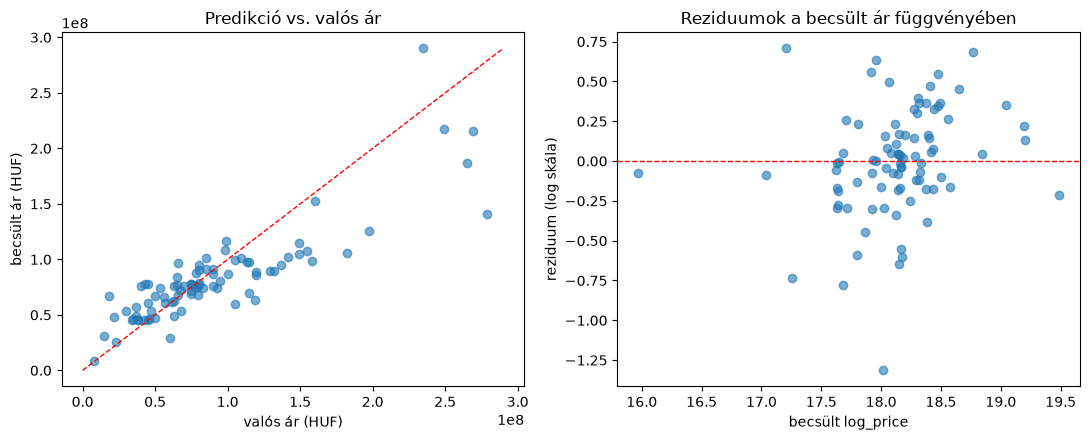

Legnagyobb abszolút hibájú teszt-sorok:


,valós_ár_HUF,becsült_ár_HUF,abs_hiba_HUF
177,279000000.0,1.409654e+08,1.380346e+08
395,265000000.0,1.864836e+08,7.851638e+07
194,182489635.0,1.058803e+08,7.660929e+07
307,197500000.0,1.253325e+08,7.216746e+07
468,158000000.0,9.876197e+07,5.923803e+07
424,118900000.0,6.302649e+07,5.587351e+07
182,235000000.0,2.900278e+08,5.502780e+07
409,269000000.0,2.156451e+08,5.335490e+07
348,17900000.0,6.664218e+07,4.874218e+07
405,155000000.0,1.077574e+08,4.724263e+07


In [8]:
X_train, X_test, y_train, y_test = split_clean
pred_test = rf_final.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(np.expm1(y_test), np.expm1(pred_test), alpha=0.6)
lims = [0, max(np.expm1(y_test).max(), np.expm1(pred_test).max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("valós ár (HUF)")
axes[0].set_ylabel("becsült ár (HUF)")
axes[0].set_title("Predikció vs. valós ár")

residuals = y_test - pred_test
axes[1].scatter(pred_test, residuals, alpha=0.6)
axes[1].axhline(0, color="r", linestyle="--", linewidth=1)
axes[1].set_xlabel("becsült log_price")
axes[1].set_ylabel("reziduum (log skála)")
axes[1].set_title("Reziduumok a becsült ár függvényében")

plt.tight_layout()
plt.show()

print("Legnagyobb abszolút hibájú teszt-sorok:")
worst = pd.DataFrame({
    "valós_ár_HUF": np.expm1(y_test),
    "becsült_ár_HUF": np.expm1(pred_test),
    "abs_hiba_HUF": np.abs(np.expm1(y_test) - np.expm1(pred_test)),
}).sort_values("abs_hiba_HUF", ascending=False).head(10)
worst


## Összefoglalás és következő lépés

- A **Random Forest** konzisztensen jobban teljesít, mint a lineáris/Ridge
  regresszió — az ár–jellemző kapcsolat nem lineáris.
- A legjobb beállítás (ház + lakás, kiugró értékek nélkül) teszt
  **R² ≈ 0,72**, **MAPE ≈ 27%** — ez egy tartható baseline egy ~400 soros,
  elsősorban terület + Budapest-távolság jellemzőkre épülő modelltől, de
  **messze nem elég pontos** egy valós ár-becslő eszközhöz.
- A legnagyobb hibaforrás vélhetően a **településszintű** árkülönbségek
  (a `dist_to_bp_km` csak Budapest-közelséget fejez ki, a többi település
  közötti eltérést nem), valamint az **állapot** (`condition` oszlop, amit
  jelenleg egyáltalán nem használ a modell) és egyéb, jelenleg nem
  gyűjtött jellemzők (pl. emelet, energetikai besorolás) hiánya.
- Következő lépésként érdemes: (1) `condition` beépítése jellemzőként,
  (2) nagyobb adatmennyiség gyűjtése (jelenleg ~450 sor, miközben a
  `settlement` kategóriák száma is nő ezzel), (3) településszintű
  csoportosított átlag-ár mint jellemző (target encoding), (4) a reziduum-
  alapú anomália-detektálás (plan.md D) pont), amint a modell stabilabb.
